# Sentiment Classification with TF-IDF, Naive Bayes and Logistic Regression

**Goal:** an NLP text classifier that labels customer/movie reviews as **positive** or **negative**: clean and tokenise text (HTML removal, lower-casing, stop-word removal, lemmatisation), turn it into
`TfidfVectorizer(max_features=5000)` features, train **MultinomialNB** and **LogisticRegression**, and expose a `predict_sentiment()` function for live phrases.

| # | Section | Key question |
|---|---|---|
| 1 | Data | The starter link is dead — what do we use, and what is in it? |
| 2 | Exploration | What do the reviews look like (length, HTML, balance)? |
| 3 | Text preprocessing | Which cleaning steps, and why is naive stop-word removal dangerous for sentiment? |
| 4 | Preprocessing ablation | Do those choices actually matter? (paired significance tests) |
| 5 | Models & tuning | NB vs Logistic Regression, brief-spec baseline vs tuned, `max_features` sensitivity |
| 6 | Test-set evaluation | Accuracy, precision/recall/F1, ROC-AUC, confusion matrices, significance |
| 7 | Interpretation & errors | Which words drive predictions? Where do the models fail? |
| 8 | Learning curves | NB or LR when data is scarce? |
| 9 | Domain shift | Do models trained on long reviews work on short phrases? |
| 10 | `predict_sentiment()` | Live prediction with confidence, explanation and an "uncertain" band |
| 11 | Conclusions | |

**Conventions.** The test set is touched only for final evaluation. Every vectoriser is fitted on training data only (inside a `Pipeline` during cross-validation), so IDF statistics never leak.

## 0. Setup

In [1]:
import warnings, re, html, time, math, urllib.request, urllib.error
from functools import lru_cache
from tempfile import mkdtemp
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest

import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

RS = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_colwidth", 140)

## 1. The data

### 1.1 The starter file is unavailable

The brief links to `datasets/sample-reviews/.../sentiment_reviews.csv`. Let's check it:

In [2]:
BRIEF_URL = "https://raw.githubusercontent.com/datasets/sample-reviews/main/sentiment_reviews.csv"
try:
    urllib.request.urlopen(BRIEF_URL, timeout=20)
    print("Brief URL is reachable")
except urllib.error.HTTPError as e:
    print(f"Brief URL → HTTP {e.code} {e.reason}: the starter file does not exist at that address.")
except Exception as e:
    print("Brief URL failed:", type(e).__name__, e)

Brief URL → HTTP 404 Not Found: the starter file does not exist at that address.


It returns **HTTP 404**, so we substitute well-known public benchmarks that fit the brief:

| Dataset | Content | Size | Role |
|---|---|---|---|
| **IMDB Large Movie Review set** (Maas et al.) | full-length movie reviews, **raw HTML included** (`<br />`) | 50,000 (25k pos / 25k neg) | primary benchmark; exercises HTML removal |
| **Rotten Tomatoes snippets** (Pang & Lee) | one-sentence review snippets | 10,662 (balanced) | short-text / domain-shift test (Section 9) |

No labelled *product*-review dataset was reachable from this environment, so product-domain behaviour is only demonstrated qualitatively in Section 10, not measured.

In [3]:
IMDB_URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
try:
    raw = pd.read_csv(IMDB_URL); src = "URL"
except Exception:
    raw = pd.read_csv("IMDB-Dataset.csv"); src = "local file"
print(f"Loaded IMDB from {src}: shape = {raw.shape}, columns = {raw.columns.tolist()}")
raw.head(3)

Loaded IMDB from URL: shape = (50000, 2), columns = ['review', 'sentiment']


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, a...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a ligh...",positive


In [4]:
audit = {
    "rows": len(raw),
    "missing values": int(raw.isna().sum().sum()),
    "exact duplicate reviews": int(raw["review"].duplicated().sum()),
    "reviews containing HTML tags": f"{raw['review'].str.contains(r'<[^>]+>').mean():.1%}",
}
display(pd.Series(audit, name="audit").to_frame())
display(raw["sentiment"].value_counts().to_frame("rows"))
print("Example of raw HTML in the data:\n", raw["review"].iloc[1][:260], "...")

,audit
rows,50000
missing values,0
exact duplicate reviews,418
reviews containing HTML tags,58.4%


,rows
sentiment,
positive,25000
negative,25000


Example of raw HTML in the data:
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael  ...


**Findings:** the labels are perfectly balanced, there are no nulls, but **418 reviews are exact duplicates**. Duplicates are a quiet source of *leakage* (the same text could land in both the train and the test set and inflate accuracy), so we drop them before splitting.
58 % of reviews contain HTML tags, so tag removal is a real requirement, not a formality.

In [5]:
df = raw.drop_duplicates("review").reset_index(drop=True)
df["y"] = (df["sentiment"] == "positive").astype(int)
df["n_words"] = df["review"].str.split().str.len()
print(f"After de-duplication: {len(df):,} reviews | positive share = {df['y'].mean():.3f}")

After de-duplication: 49,582 reviews | positive share = 0.502


## 2. Exploration

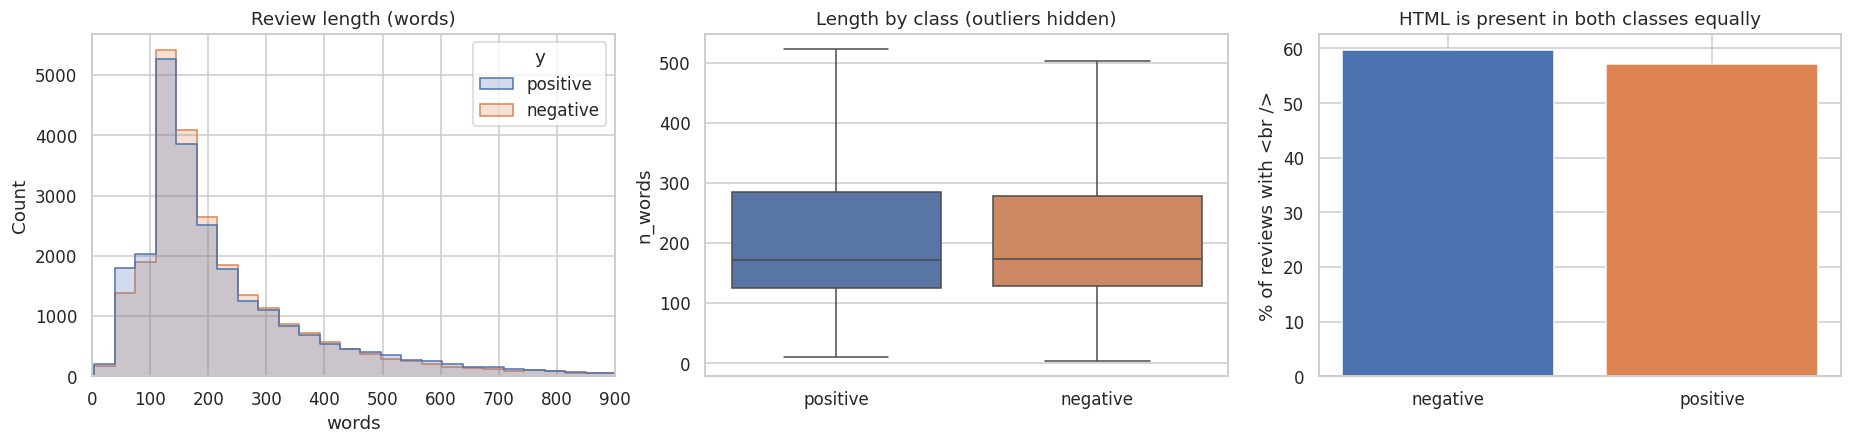

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
negative,"24,698.0000",229.6000,165.1000,4.0000,128.0000,174.0000,278.0000,"1,522.0000"
positive,"24,884.0000",233.1000,177.7000,10.0000,125.0000,172.0000,284.0000,"2,470.0000"


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(data=df, x="n_words", hue=df["y"].map({0: "negative", 1: "positive"}), bins=70, element="step", ax=axes[0])
axes[0].set_xlim(0, 900); axes[0].set_title("Review length (words)"); axes[0].set_xlabel("words")
sns.boxplot(data=df, x=df["y"].map({0: "negative", 1: "positive"}), y="n_words", showfliers=False, ax=axes[1], hue=df["y"].map({0: "negative", 1: "positive"}), legend=False)
axes[1].set_title("Length by class (outliers hidden)"); axes[1].set_xlabel("")
html_share = df.groupby("y")["review"].apply(lambda s: s.str.contains("<br />").mean())
axes[2].bar(["negative", "positive"], html_share.values * 100, color=["C0", "C1"]); axes[2].set_ylabel("% of reviews with <br />")
axes[2].set_title("HTML is present in both classes equally")
plt.tight_layout(); plt.show()
display(df.groupby("y")["n_words"].describe().rename(index={0: "negative", 1: "positive"}).round(1))

**What the exploration says**

- **Balanced, clean labels.** After de-duplication 50.2 % of reviews are positive; there are no missing values, so accuracy is a fair headline metric (a majority-class guesser scores ≈ 50 %).
- **Length carries no class signal.** Negative and positive reviews have almost identical length distributions (mean 230 vs 233 words, median 174 vs 172), so the model cannot "cheat" by review length. There is a long right tail (up to 2,470 words).
- **HTML is everywhere** (≈ 60 % of negative and 57 % of positive reviews contain `<br />`). Left in, tokens like `br` would become spurious features; removing tags is genuine hygiene, not just a formality.
- **Typical review ≈ 175 words** (median). Remember this number: the one-sentence phrases a user will type live are ~10× shorter, which matters in Section 9.

## 3. Text preprocessing

Steps, in order:

1. **Strip HTML tags** (`<br />`, `<p>`, …) and decode entities (`&amp;` → `&`).
2. **Remove URLs.**
3. **Lower-case.**
4. **Expand contractions**: `didn't` → `did not`, `won't` → `will not`, `can't` → `can not`, other clitics (`'re`, `'ve`, `'ll`, `'d`, `'m`, `'s`) dropped. This is done *before* tokenising so that negation survives as the word `not`.
5. **Tokenise** with a regex that keeps alphabetic words (digits and punctuation are dropped; clause punctuation is only used internally for negation scope).
6. **Remove stop-words**, using NLTK's English list **minus the negations** (`no`, `nor`, `not`; `never` is not in the list anyway).
7. **Lemmatise** with WordNet (verb pass then noun pass: *loved → love*, *movies → movie*, *was → be*), cached per word for speed.

**Why not remove *all* NLTK stop-words?** The standard list contains `not`, `no`, `nor` and fragments like `didn`, `wasn`, `couldn`. Dropping them turns *"not good"* into *"good"* and *"I didn't like it"* into *"like"*, flipping the meaning.
The code below makes the stop-word policy a parameter so we can measure the effect in Section 4.

In [7]:
STOP = set(stopwords.words("english"))
NEGATIONS = {"no", "nor", "not", "never"}
_wnl = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemmatize(word):
    return _wnl.lemmatize(_wnl.lemmatize(word, "v"), "n")

_TAG = re.compile(r"<[^>]+>")
_URL = re.compile(r"https?://\S+|www\.\S+")
_TOKEN = re.compile(r"[a-z]+|[.!?;:,]")
_CONTRACTIONS = [(r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bcannot\b", "can not"),
                 (r"n't\b", " not"), (r"'(?:re|ve|ll|d|m|s)\b", "")]

def clean_text(text):
    '''Steps 1-4: HTML, URLs, lower-casing, contractions.'''
    if not isinstance(text, str):
        return ""
    text = html.unescape(_TAG.sub(" ", text)).replace("\u2019", "'")
    text = _URL.sub(" ", text).lower()
    for pat, rep in _CONTRACTIONS:
        text = re.sub(pat, rep, text)
    return text

def preprocess(text, stop="keep_negations", lemma=True, mark_negation=False, neg_scope=3):
    '''Full pipeline -> a space-separated string of tokens.
    stop: "keep_negations" (default) | "naive" (drop every NLTK stop-word) | "none" (keep all)
    mark_negation: prefix the next `neg_scope` words after a negator (until punctuation) with "not_".'''
    out, scope = [], 0
    for w in _TOKEN.findall(clean_text(text)):
        if w in ".!?;:,":
            scope = 0; continue
        if len(w) < 2:
            continue
        if stop == "naive" and w in STOP:
            continue
        if stop == "keep_negations" and w in STOP and w not in NEGATIONS:
            continue
        if lemma:
            w = lemmatize(w)
        if mark_negation:
            if w in NEGATIONS:
                scope = neg_scope; out.append(w); continue
            if scope > 0:
                out.append("not_" + w); scope -= 1; continue
        out.append(w)
    return " ".join(out)

def preprocess_batch(texts, **kw):
    return [preprocess(t, **kw) for t in texts]

# ---- unit tests: the cleaning behaves as specified
assert preprocess("<br />Great!<br />") == "great"
assert preprocess("I didn't like it") == "not like"
assert preprocess("It won't work, can't use") == "not work not use"
assert preprocess("The movies were running &amp; fun", stop="keep_negations") == "movie run fun"
assert preprocess("") == "" and preprocess(None) == "" and preprocess("!!! ??? 123") == ""
assert "http" not in preprocess("see https://example.com/x now great")
assert preprocess("not good").split() == ["not", "good"]
assert preprocess("not good", stop="naive") == "good"                       # the failure mode we avoid
assert "not_good" in preprocess("it was not good, honestly", mark_negation=True).split()
print("all preprocessing unit tests passed")

all preprocessing unit tests passed


In [8]:
examples = [
    "I <b>loved</b> this film!<br /><br />The acting wasn't bad, and the movies' soundtrack is great :) http://x.co",
    "I didn't like it. It's NOT a good movie, can't recommend.",
]
for e in examples:
    print("RAW        :", e)
    print("naive stop :", preprocess(e, stop="naive"))
    print("keep neg.  :", preprocess(e))
    print("+ not_ mark:", preprocess(e, mark_negation=True), "\n")

RAW        : I <b>loved</b> this film!<br /><br />The acting wasn't bad, and the movies' soundtrack is great :) http://x.co
naive stop : love film act bad movie soundtrack great
keep neg.  : love film act not bad movie soundtrack great
+ not_ mark: love film act not not_bad movie soundtrack great 

RAW        : I didn't like it. It's NOT a good movie, can't recommend.
naive stop : like good movie recommend
keep neg.  : not like not good movie not recommend
+ not_ mark: not not_like not not_good not_movie not not_recommend 



Note how *naive* stop-word removal turns the second example into "like good recommend", i.e. an apparently **positive** text, while the negation-aware version keeps `not like not good not recommend`-style evidence.

## 4. Does the preprocessing choice matter? (ablation on a validation split)

First we lock away the test set (stratified 80/20) and from the training portion carve out an **inner validation split** (another 80/20). Each preprocessing variant is scored with `TfidfVectorizer(max_features=5000)` + NB / LR on that inner split.
Because all variants are scored on the *same* validation reviews, we compare them with a **paired exact McNemar test** against the reference variant, which is more sensitive than comparing overlapping confidence intervals.

In [9]:
idx = np.arange(len(df))
idx_train, idx_test = train_test_split(idx, test_size=0.20, stratify=df["y"], random_state=RS)
idx_sub, idx_val = train_test_split(idx_train, test_size=0.20, stratify=df["y"].values[idx_train], random_state=RS)
print(f"Train {len(idx_train):,} | Test {len(idx_test):,}   (ablation uses sub-train {len(idx_sub):,} / validation {len(idx_val):,})")

def tfidf(ngram=(1, 1), max_features=5000):
    # input is already cleaned, space-separated tokens -> split on whitespace, no further lower-casing
    return TfidfVectorizer(max_features=max_features, ngram_range=ngram, token_pattern=None, tokenizer=str.split, lowercase=False)

def mcnemar_p(pred_a, pred_b, y):
    a_ok, b_ok = pred_a == y, pred_b == y
    n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return 1.0 if n01 + n10 == 0 else binomtest(n01, n01 + n10, 0.5).pvalue

variants = {
    "naive stop-words (drop negations)": dict(stop="naive"),
    "keep negations  [reference]":        dict(stop="keep_negations"),
    "keep negations + not_ marking":      dict(stop="keep_negations", mark_negation=True),
    "no stop-word removal":               dict(stop="none"),
    "keep negations, no lemmatisation":   dict(stop="keep_negations", lemma=False),
}
REF = "keep negations  [reference]"
y_sub, y_val = df["y"].values[idx_sub], df["y"].values[idx_val]
store, abl_rows = {}, []
for name, kw in variants.items():
    t0 = time.time()
    Xs = preprocess_batch(df["review"].to_numpy(dtype=object)[idx_sub], **kw); Xv = preprocess_batch(df["review"].to_numpy(dtype=object)[idx_val], **kw)
    for ng in [(1, 1), (1, 2)]:
        v = tfidf(ng); A = v.fit_transform(Xs); B = v.transform(Xv)
        for mname, m in [("NB", MultinomialNB(alpha=0.5)), ("LR", LogisticRegression(C=4, max_iter=2000))]:
            store[(name, ng, mname)] = m.fit(A, y_sub).predict(B)
    print(f"{name:38s} done in {time.time() - t0:.0f}s", flush=True)

for (name, ng, mname), pred in store.items():
    ref = store[(REF, ng, mname)]
    abl_rows.append({"Variant": name, "n-grams": f"{ng[0]}-{ng[1]}", "Model": mname, "Val accuracy": (pred == y_val).mean(),
                     "Δ vs reference (pts)": 100 * ((pred == y_val).mean() - (ref == y_val).mean()), "McNemar p": mcnemar_p(pred, ref, y_val)})
abl = pd.DataFrame(abl_rows)
wide = abl.pivot_table(index="Variant", columns=["Model", "n-grams"], values="Val accuracy").loc[list(variants)]
display(wide.style.format("{:.4f}").set_caption(f"Validation accuracy (n = {len(idx_val):,}; 1 SE ≈ {100*np.sqrt(.88*.12/len(idx_val)):.2f} pts)"))
sig = abl[abl["Variant"] != REF].copy()
display(sig.style.format({"Val accuracy": "{:.4f}", "Δ vs reference (pts)": "{:+.2f}", "McNemar p": "{:.3f}"}).hide(axis="index"))

Train 39,665 | Test 9,917   (ablation uses sub-train 31,732 / validation 7,933)


naive stop-words (drop negations)      done in 27s


keep negations  [reference]            done in 24s


keep negations + not_ marking          done in 26s


no stop-word removal                   done in 29s


keep negations, no lemmatisation       done in 27s


Variant,n-grams,Model,Val accuracy,Δ vs reference (pts),McNemar p
naive stop-words (drop negations),1-1,NB,0.8443,+0.10,0.280
naive stop-words (drop negations),1-1,LR,0.8811,-0.29,0.054
naive stop-words (drop negations),1-2,NB,0.8550,-0.35,0.062
naive stop-words (drop negations),1-2,LR,0.8881,-0.43,0.030
keep negations + not_ marking,1-1,NB,0.8479,+0.45,0.039
keep negations + not_ marking,1-1,LR,0.8874,+0.34,0.155
keep negations + not_ marking,1-2,NB,0.8592,+0.06,0.803
keep negations + not_ marking,1-2,LR,0.8921,-0.03,0.952
no stop-word removal,1-1,NB,0.8429,-0.04,0.865
no stop-word removal,1-1,LR,0.8874,+0.34,0.113


**What the ablation says: preprocessing is not where the accuracy comes from.**

- Every variant lands within about ±0.8 points of the reference (LR 88.1–89.2 %, NB 84.3–86.0 %).
- Of the 16 hypothesis tests, 5 have p < 0.05, but with 16 tests about one would be expected by chance, **none survives a Bonferroni correction** (0.05 / 16 ≈ 0.003), and the signs are inconsistent: skipping lemmatisation helps unigram NB by +0.67 points (p = 0.007) yet changes bigram NB by −0.04.
- **The one consistent pattern is about negations.** Naive stop-word removal (which deletes `not`) is slightly worse in 3 of the 4 configurations (−0.29 to −0.43 points, p = 0.03–0.06), while the negation-aware list is never reliably worse.
- **Explicit `not_` marking helps unigram models** (+0.34 points LR, +0.45 NB) **but the benefit disappears once bigrams are used** (−0.03 and +0.06): the bigram `not good` already captures local negation.
- Keeping *all* stop-words is clearly worse for bigram NB (−0.82 points, p = 0.009; the strongest single effect), most likely because stop-word bigrams such as "of the" crowd the 5,000-feature budget.

**Decision:** keep the reference pipeline (negation-aware stop-words + lemmatisation) with **unigram + bigram** features. It is the principled choice and is never reliably worse; the evidence just says the choice is low-stakes.

## 5. Models and tuning

### 5.1 Pre-process everything once

We use the chosen preprocessing (**keep negations, lemmatise**) for all 49,582 reviews and cache the result, so that every later experiment re-uses the same cleaned text.

In [10]:
t0 = time.time()
df["clean"] = preprocess_batch(df["review"].to_numpy(dtype=object))
print(f"Cleaned {len(df):,} reviews in {time.time() - t0:.0f}s")
display(df.loc[[1, 2], ["review", "clean"]].assign(review=lambda d: d["review"].str[:230] + "…", clean=lambda d: d["clean"].str[:230] + "…"))
X_train, X_test = df["clean"].to_numpy(dtype=object)[idx_train], df["clean"].to_numpy(dtype=object)[idx_test]
y_train, y_test = df["y"].values[idx_train], df["y"].values[idx_test]
raw_test = df["review"].to_numpy(dtype=object)[idx_test]

# vocabulary shrinkage
v_all = TfidfVectorizer(token_pattern=None, tokenizer=str.split, lowercase=False).fit(X_train)
v_raw = TfidfVectorizer().fit(df["review"].to_numpy(dtype=object)[idx_train])
print(f"Vocabulary size: raw text (sklearn default tokenising) = {len(v_raw.vocabulary_):,}  →  after our preprocessing = {len(v_all.vocabulary_):,}  →  max_features = 5,000")

Cleaned 49,582 reviews in 8s


,review,clean
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, a...",wonderful little production film technique unassuming old time bbc fashion give comfort sometimes discomforting sense realism entire pie...
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a ligh...",think wonderful way spend time hot summer weekend sit air condition theater watch light hearted comedy plot simplistic dialogue witty ch...


Vocabulary size: raw text (sklearn default tokenising) = 92,953  →  after our preprocessing = 72,661  →  max_features = 5,000


### 5.2 Baseline exactly as specified, then tuned

*Baseline* = what the brief literally asks for: `TfidfVectorizer(max_features=5000)` (unigrams) with `MultinomialNB()` and `LogisticRegression()` at their default settings.
*Tuned* = 3-fold `GridSearchCV` on the training set over the n-gram range (unigram vs unigram+bigram, still `max_features=5000`) and the model's regularisation strength (NB smoothing `alpha`, LR inverse-regularisation `C`).
The vectoriser sits **inside** the pipeline, so IDF is re-fitted on each training fold, and the fitted vectoriser is cached across the classifier-parameter grid to keep the search fast.

In [11]:
MEM = mkdtemp()
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)

grid_nb = {"tfidf__ngram_range": [(1, 1), (1, 2)], "clf__alpha": [0.03, 0.1, 0.3, 0.5, 1.0]}
grid_lr = {"tfidf__ngram_range": [(1, 1), (1, 2)], "clf__C": [0.3, 1, 3, 10, 30]}

t0 = time.time()
gs_nb = GridSearchCV(Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB())], memory=MEM), grid_nb, cv=cv3, scoring="accuracy").fit(X_train, y_train)
gs_lr = GridSearchCV(Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=3000))], memory=MEM), grid_lr, cv=cv3, scoring="accuracy").fit(X_train, y_train)
print(f"Grid searches finished in {time.time() - t0:.0f}s")
for nm, g in [("MultinomialNB", gs_nb), ("LogisticRegression", gs_lr)]:
    print(f"{nm:20s} best CV accuracy = {g.best_score_:.4f}   params = {g.best_params_}")

Grid searches finished in 133s
MultinomialNB        best CV accuracy = 0.8594   params = {'clf__alpha': 0.5, 'tfidf__ngram_range': (1, 2)}
LogisticRegression   best CV accuracy = 0.8903   params = {'clf__C': 3, 'tfidf__ngram_range': (1, 2)}


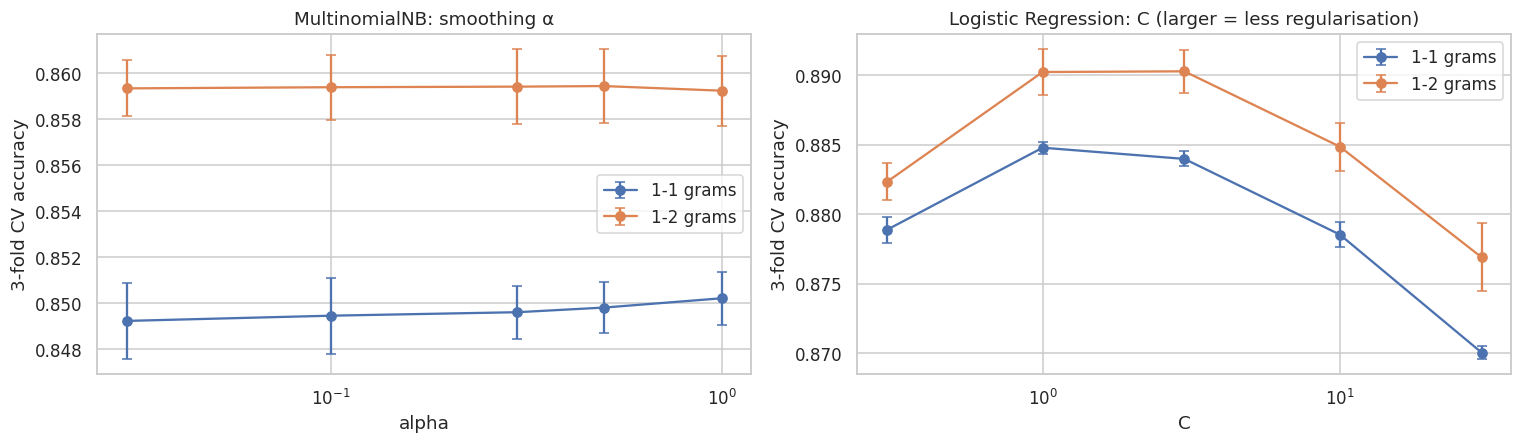

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, g, pname, ttl in [(axes[0], gs_nb, "clf__alpha", "MultinomialNB: smoothing α"), (axes[1], gs_lr, "clf__C", "Logistic Regression: C (larger = less regularisation)")]:
    r = pd.DataFrame(g.cv_results_)
    r["ngram"] = r["param_tfidf__ngram_range"].map(lambda t: f"{t[0]}-{t[1]} grams")
    for ng, d in r.groupby("ngram"):
        ax.errorbar(d[f"param_{pname}"].astype(float), d["mean_test_score"], yerr=d["std_test_score"], marker="o", capsize=3, label=ng)
    ax.set_xscale("log"); ax.set_xlabel(pname.split("__")[1]); ax.set_ylabel("3-fold CV accuracy"); ax.set_title(ttl); ax.legend()
plt.tight_layout(); plt.show()

### 5.3 How many features? (`max_features` sensitivity)

The brief fixes `max_features=5000`. Is that a good value? Using the tuned settings and the inner validation split (vectoriser re-fitted for each size):

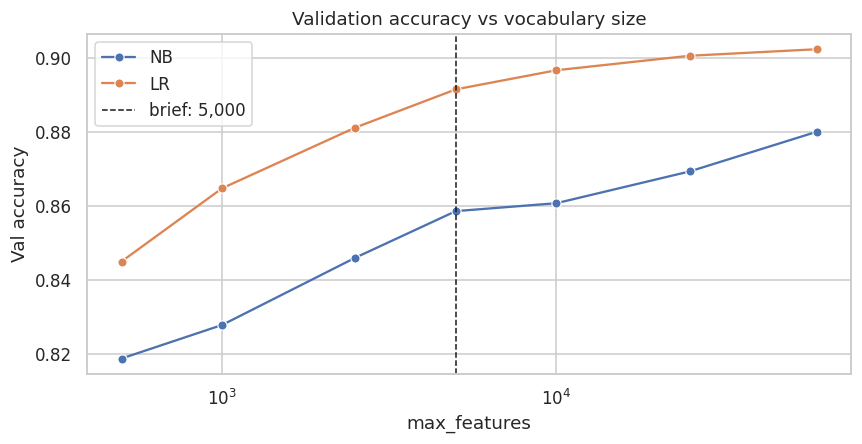

Model,LR,NB
max_features,,
500,0.8450,0.8187
1000,0.8647,0.8278
2500,0.8811,0.8460
5000,0.8915,0.8586
10000,0.8966,0.8607
25000,0.9005,0.8693
60000,0.9023,0.8800


In [13]:
Xs_c, Xv_c = df["clean"].to_numpy(dtype=object)[idx_sub], df["clean"].to_numpy(dtype=object)[idx_val]
ng_nb, ng_lr = gs_nb.best_params_["tfidf__ngram_range"], gs_lr.best_params_["tfidf__ngram_range"]
rows = []
for mf in [500, 1000, 2500, 5000, 10000, 25000, 60000]:
    for mname, ng, mk in [("NB", ng_nb, lambda: MultinomialNB(alpha=gs_nb.best_params_["clf__alpha"])),
                          ("LR", ng_lr, lambda: LogisticRegression(C=gs_lr.best_params_["clf__C"], max_iter=3000))]:
        v = tfidf(ng, mf); A = v.fit_transform(Xs_c); B = v.transform(Xv_c)
        rows.append({"max_features": mf, "Model": mname, "Val accuracy": mk().fit(A, y_sub).score(B, y_val)})
mfdf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.lineplot(data=mfdf, x="max_features", y="Val accuracy", hue="Model", marker="o", ax=ax)
ax.axvline(5000, color="k", ls="--", lw=1, label="brief: 5,000"); ax.set_xscale("log"); ax.set_title("Validation accuracy vs vocabulary size"); ax.legend()
plt.tight_layout(); plt.show()
display(mfdf.pivot(index="max_features", columns="Model", values="Val accuracy").style.format("{:.4f}"))

**How much does the 5,000-feature cap cost?** Accuracy keeps rising with vocabulary size: Logistic Regression goes from 84.5 % (500 features) to 89.2 % (5,000) to **90.2 % (60,000)**, and Naive Bayes from 81.9 % to 85.9 % to **88.0 %**.
So the brief's 5,000 captures most of the gain (the curve is flattening) but still leaves **≈ 1.1 points on the table for LR and ≈ 2.1 for NB** compared with a 60k vocabulary (our cleaned vocabulary has 72,661 terms, so 5,000 keeps only ≈ 7 % of them). That is a bigger lever than any preprocessing choice in Section 4.
We keep `max_features=5000` for the rest of the notebook because the brief specifies it, but if accuracy matters more than model size, raising it to 25,000–60,000 is a free improvement.

## 6. Test-set evaluation

All four models are scored once on the untouched test set of 9,917 reviews: the two baselines exactly as specified and the two tuned models.

In [14]:
baselines = {
    "NB (brief spec: defaults)": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB())]).fit(X_train, y_train),
    "LR (brief spec: defaults)": Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=3000))]).fit(X_train, y_train),
}
tuned = {"NB (tuned)": gs_nb.best_estimator_, "LR (tuned)": gs_lr.best_estimator_}
models = {**baselines, **tuned}
proba = {k: m.predict_proba(X_test)[:, 1] for k, m in models.items()}
pred = {k: (p >= 0.5).astype(int) for k, p in proba.items()}

rows = []
for k in models:
    rows.append({"Model": k, "Accuracy": accuracy_score(y_test, pred[k]), "Precision": precision_score(y_test, pred[k]),
                 "Recall": recall_score(y_test, pred[k]), "F1": f1_score(y_test, pred[k]), "ROC-AUC": roc_auc_score(y_test, proba[k])})
res = pd.DataFrame(rows).set_index("Model")

# 95% bootstrap CI on accuracy
rng = np.random.default_rng(RS); B = 2000
bidx = rng.integers(0, len(y_test), size=(B, len(y_test)))
boot_acc = {k: ((pred[k][bidx] == y_test[bidx]).mean(axis=1)) for k in models}
res["Acc 95% CI low"] = [np.percentile(boot_acc[k], 2.5) for k in res.index]; res["Acc 95% CI high"] = [np.percentile(boot_acc[k], 97.5) for k in res.index]
display(res.style.format("{:.4f}").background_gradient(subset=["Accuracy", "ROC-AUC"], cmap="Greens"))
print(f"Majority-class baseline accuracy: {max(y_test.mean(), 1 - y_test.mean()):.3f}")

,Accuracy,Precision,Recall,F1,ROC-AUC,Acc 95% CI low,Acc 95% CI high
Model,,,,,,,
NB (brief spec: defaults),0.8562,0.8526,0.8626,0.8576,0.9289,0.8493,0.8634
LR (brief spec: defaults),0.8894,0.8814,0.9007,0.8910,0.9569,0.8830,0.8956
NB (tuned),0.8603,0.8519,0.8736,0.8626,0.9358,0.8533,0.8675
LR (tuned),0.8954,0.8875,0.9066,0.8969,0.9618,0.8891,0.9013


Majority-class baseline accuracy: 0.502


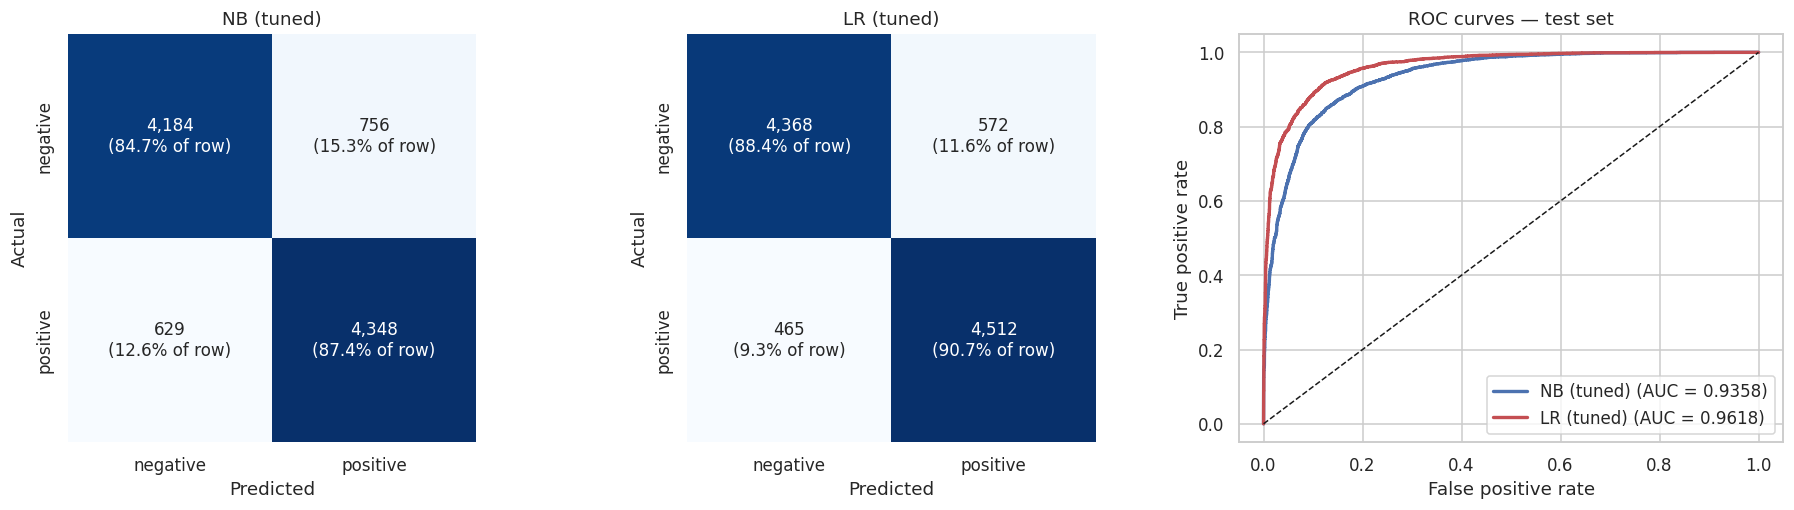

--- NB (tuned) ---
              precision    recall  f1-score   support

    negative     0.8693    0.8470    0.8580      4940
    positive     0.8519    0.8736    0.8626      4977

    accuracy                         0.8603      9917
   macro avg     0.8606    0.8603    0.8603      9917
weighted avg     0.8606    0.8603    0.8603      9917

--- LR (tuned) ---
              precision    recall  f1-score   support

    negative     0.9038    0.8842    0.8939      4940
    positive     0.8875    0.9066    0.8969      4977

    accuracy                         0.8954      9917
   macro avg     0.8956    0.8954    0.8954      9917
weighted avg     0.8956    0.8954    0.8954      9917



In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, k in zip(axes[:2], ["NB (tuned)", "LR (tuned)"]):
    cm = confusion_matrix(y_test, pred[k])
    sns.heatmap(cm, annot=np.array([[f"{v:,}\n({v / cm.sum(1)[i]:.1%} of row)" for v in row] for i, row in enumerate(cm)]), fmt="", cmap="Blues", cbar=False, square=True,
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"], ax=ax, annot_kws={"size": 11})
    ax.set_title(f"{k}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for k, c in [("NB (tuned)", "C0"), ("LR (tuned)", "C3")]:
    fpr, tpr, _ = roc_curve(y_test, proba[k]); axes[2].plot(fpr, tpr, color=c, lw=2.2, label=f"{k} (AUC = {roc_auc_score(y_test, proba[k]):.4f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].set_title("ROC curves — test set"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()
for k in ["NB (tuned)", "LR (tuned)"]:
    print(f"--- {k} ---"); print(classification_report(y_test, pred[k], target_names=["negative", "positive"], digits=4))

LR right & NB wrong: 672 | NB right & LR wrong: 324
McNemar exact p-value = 1.11e-28
Accuracy gap LR − NB = 3.50 pts   (95% bootstrap CI 2.86 to 4.13)


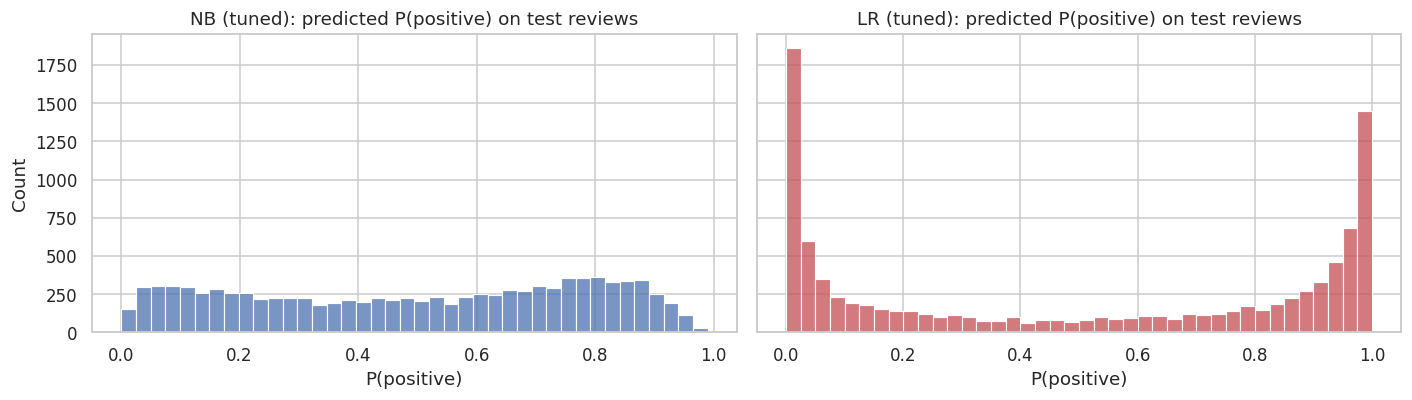

Share of test predictions with P(positive) < 0.05 or > 0.95:  NB (tuned): 5.4% | LR (tuned): 46.2%


In [16]:
# Is the LR > NB gap real?  paired exact McNemar test + paired bootstrap on the same test reviews
p = mcnemar_p(pred["LR (tuned)"], pred["NB (tuned)"], y_test)
d = boot_acc["LR (tuned)"] - boot_acc["NB (tuned)"]
lr_ok, nb_ok = pred["LR (tuned)"] == y_test, pred["NB (tuned)"] == y_test
print(f"LR right & NB wrong: {int((lr_ok & ~nb_ok).sum()):,} | NB right & LR wrong: {int((~lr_ok & nb_ok).sum()):,}")
print(f"McNemar exact p-value = {p:.2e}")
print(f"Accuracy gap LR − NB = {100 * d.mean():.2f} pts   (95% bootstrap CI {100 * np.percentile(d, 2.5):.2f} to {100 * np.percentile(d, 97.5):.2f})")

# predicted-probability behaviour: relevant for the confidence shown by predict_sentiment()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, k, c in [(axes[0], "NB (tuned)", "C0"), (axes[1], "LR (tuned)", "C3")]:
    sns.histplot(proba[k], bins=40, color=c, ax=ax); ax.set_title(f"{k}: predicted P(positive) on test reviews"); ax.set_xlabel("P(positive)")
plt.tight_layout(); plt.show()
print("Share of test predictions with P(positive) < 0.05 or > 0.95:  " + " | ".join(f"{k}: {((proba[k] < .05) | (proba[k] > .95)).mean():.1%}" for k in ["NB (tuned)", "LR (tuned)"]))

**Test results (9,917 held-out reviews)**

| Model | Accuracy | 95 % CI | F1 | ROC-AUC |
|---|---|---|---|---|
| NB, brief spec (unigrams, defaults) | 0.856 | 0.849–0.863 | 0.858 | 0.929 |
| NB, tuned (1–2-grams, α = 0.5) | 0.860 | 0.853–0.868 | 0.863 | 0.936 |
| LR, brief spec (unigrams, defaults) | 0.889 | 0.883–0.896 | 0.891 | 0.957 |
| **LR, tuned (1–2-grams, C = 3)** | **0.895** | **0.889–0.901** | **0.897** | **0.962** |

- **Tuning helped only a little** (+0.4 points NB, +0.6 LR; the confidence intervals overlap). The brief's default settings were already close to optimal.
- **Logistic Regression beats Naive Bayes by 3.5 points** (95 % bootstrap CI 2.9–4.1; exact McNemar p ≈ 10⁻²⁸): LR was right where NB was wrong on 672 reviews versus 324 the other way. This is a real difference, not noise.
- Both are far above the 50 % baseline and well balanced across classes (precision and recall within ≈ 2 points). Both lean slightly toward predicting "positive" (NB recall 0.874 on positives vs 0.847 on negatives; LR 0.907 vs 0.884).
- **Confidence behaves differently.** LR is decisive (46 % of its test probabilities are below 0.05 or above 0.95), whereas NB's probabilities are compressed toward 0.5 (only 5.4 % are that extreme), the opposite of the textbook "Naive Bayes is over-confident" warning. A likely reason is that L2-normalised TF-IDF values are small fractions, so NB's summed log-likelihoods stay small. Practically: **treat NB's probabilities as a relative score, not a calibrated probability**, and expect its "uncertain" band (Section 10) to trigger more often.

## 7. Interpretation and error analysis

### 7.1 Which words drive each model?

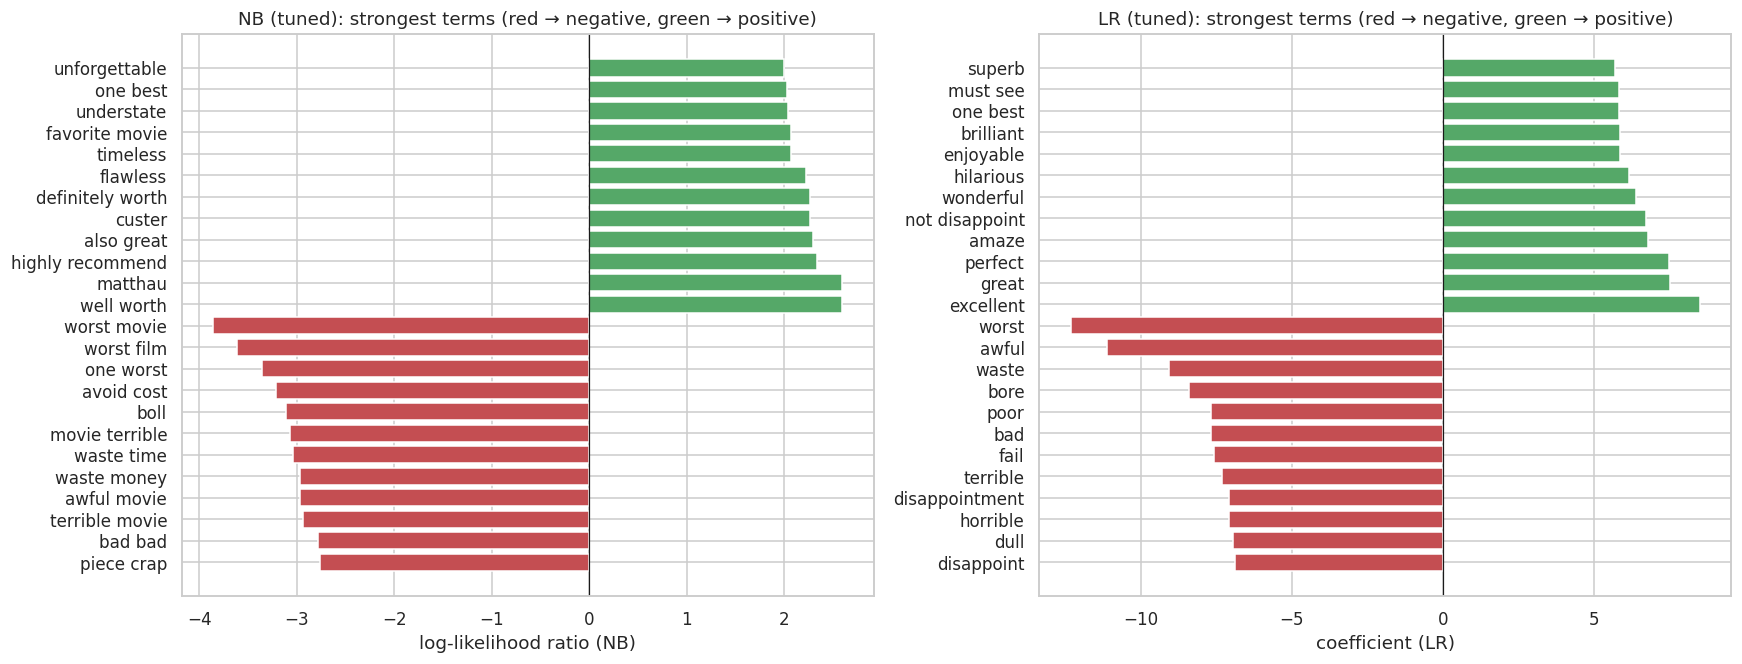

Overlap of the top-25 positive terms: 5/25 | negative terms: 2/25


,negative,neg weight,positive,pos weight
0,worst,-12.3182,excellent,8.4935
1,awful,-11.1103,great,7.5174
2,waste,-9.0730,perfect,7.4707
3,bore,-8.3906,amaze,6.7619
4,poor,-7.6935,not disappoint,6.7257
5,bad,-7.6853,wonderful,6.3628
6,fail,-7.5914,hilarious,6.1539
7,terrible,-7.3117,enjoyable,5.8617
8,disappointment,-7.0906,brilliant,5.8543
9,horrible,-7.0892,one best,5.8299


In [17]:
def top_terms(pipe, k=15, kind="lr"):
    names = np.array(pipe.named_steps["tfidf"].get_feature_names_out())
    clf = pipe.named_steps["clf"]
    w = clf.coef_[0] if kind == "lr" else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]   # NB: log-likelihood ratio pos vs neg
    o = np.argsort(w)
    return pd.DataFrame({"negative": names[o[:k]], "neg weight": w[o[:k]], "positive": names[o[::-1][:k]][:k], "pos weight": w[o[::-1][:k]]})

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, (nm, pipe, kind) in zip(axes, [("NB (tuned)", tuned["NB (tuned)"], "nb"), ("LR (tuned)", tuned["LR (tuned)"], "lr")]):
    t = top_terms(pipe, 12, kind)
    ax.barh(list(t["negative"][::-1]) + list(t["positive"]), list(t["neg weight"][::-1]) + list(t["pos weight"][::-1][::-1]),
            color=["C3"] * 12 + ["C2"] * 12)
    ax.axvline(0, color="k", lw=.8); ax.set_title(f"{nm}: strongest terms (red → negative, green → positive)")
    ax.set_xlabel("log-likelihood ratio (NB)" if kind == "nb" else "coefficient (LR)")
plt.tight_layout(); plt.show()

nb_t, lr_t = top_terms(tuned["NB (tuned)"], 25, "nb"), top_terms(tuned["LR (tuned)"], 25, "lr")
print(f"Overlap of the top-25 positive terms: {len(set(nb_t['positive']) & set(lr_t['positive']))}/25 | negative terms: {len(set(nb_t['negative']) & set(lr_t['negative']))}/25")
display(lr_t.head(12))

### 7.2 Where do the models fail?

In [18]:
lr_p = proba["LR (tuned)"]
err = pd.DataFrame({"raw": raw_test, "y": y_test, "p_lr": lr_p, "p_nb": proba["NB (tuned)"], "n_words": df["n_words"].values[idx_test]})
err["lr_wrong"] = (lr_p >= .5).astype(int) != y_test
err["conf_wrong"] = np.where(err.lr_wrong, np.abs(lr_p - .5), -1)

print("Most confident LR mistakes (text truncated):\n")
for _, r in err.sort_values("conf_wrong", ascending=False).head(5).iterrows():
    print(f"[true = {'positive' if r.y else 'negative'} | LR P(pos) = {r.p_lr:.3f} | NB P(pos) = {r.p_nb:.3f} | {r.n_words} words]")
    print("   ", re.sub(r"<[^>]+>", " ", r.raw)[:330].replace("\n", " "), "...\n")

bins = pd.qcut(err["n_words"], 5)
by_len = err.groupby(bins, observed=True).apply(lambda d: pd.Series({
    "n": len(d), "LR accuracy": 1 - d.lr_wrong.mean(), "NB accuracy": ((d.p_nb >= .5).astype(int) == d.y).mean()}))
display(by_len.style.format({"n": "{:.0f}", "LR accuracy": "{:.3f}", "NB accuracy": "{:.3f}"}).set_caption("Accuracy by review length (quintiles of word count)"))

# do mistakes concentrate where the model is unsure?
conf = np.abs(lr_p - .5) * 2
cb = pd.cut(conf, [0, .2, .4, .6, .8, 1.0], include_lowest=True)
display(pd.DataFrame({"conf": cb, "wrong": err.lr_wrong.values}).groupby("conf", observed=True)["wrong"].agg(["size", "mean"]).rename(columns={"size": "reviews", "mean": "error rate"})
        .style.format({"error rate": "{:.1%}", "reviews": "{:.0f}"}).set_caption("LR error rate by confidence |2p−1|"))

Most confident LR mistakes (text truncated):

[true = positive | LR P(pos) = 0.001 | NB P(pos) = 0.078 | 383 words]
    **SPOILERS AHEAD**  It is really unfortunate that a movie so well produced turns out to be  such a disappointment. I thought this was full of (silly) clichés and  that it basically tried to hard.   To the (American) guys out there: how many of you spend your  time jumping on your girlfriend's bed and making monkey  sounds? To th ...

[true = negative | LR P(pos) = 0.998 | NB P(pos) = 0.795 | 134 words]
    this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gent ...

[true = positive | LR P(pos) = 0.005 | NB P(pos) = 0.298 | 713 words]
    "Comanche Moon" had everything going for it. For starters, S

,n,LR accuracy,NB accuracy
n_words,,,
"(7.999, 118.0]",2024,0.897,0.874
"(118.0, 150.0]",1986,0.892,0.860
"(150.0, 203.0]",1955,0.896,0.856
"(203.0, 320.0]",1976,0.898,0.857
"(320.0, 2278.0]",1976,0.895,0.855


,reviews,error rate
conf,,
"(-0.001, 0.2]",659,42.2%
"(0.2, 0.4]",772,34.6%
"(0.4, 0.6]",1026,21.5%
"(0.6, 0.8]",1494,10.4%
"(0.8, 1.0]",5966,1.9%


**What the models learned**

- **LR's strongest terms are plain sentiment words** (*excellent, great, perfect, amazing* vs *worst, awful, waste, bore*) plus useful bigrams: `not disappoint` is among its top positive features, a case where the bigram captured a negation.
- **NB's strongest terms are mostly bigrams and include corpus-specific names** (e.g. *matthau*, *custer*, *boll*): Naive Bayes' log-likelihood ratio rewards rare words whose few occurrences happen to be lopsided. Only 5 of the top-25 positive and 2 of the top-25 negative terms are shared by the two models. This over-weighting of rare, domain-specific terms is a plausible reason for NB's lower accuracy and weaker transfer.

**Where they fail**

- **Length is not the issue for LR**: accuracy is flat across review-length quintiles (0.892–0.898); NB is somewhat better on the shortest quintile (0.874) than on longer ones (0.855–0.860).
- **Errors concentrate where the model is unsure**: LR's error rate is **1.9 %** in its most confident bucket (60 % of all reviews), 10.4 % at moderate confidence, 21.5 % in the 0.4–0.6 bucket and 35–42 % below that. So |2p − 1| is a usable reliability signal, which justifies the "uncertain" band in `predict_sentiment()`.
- **The most confident mistakes mostly look like label noise or irony, not model stupidity**: in the five shown, a "positive" review calls the film "such a disappointment", a "negative" review says "I love the five episodes", another "negative" review says the author was "blown away" by how entertaining the film is, and one "positive" review praises a film for being so bad it is funny. I cannot verify the labels, but several appear contradictory, which suggests a ceiling on achievable accuracy below 100 %.

## 8. Learning curves: NB vs Logistic Regression as data grows

A classic claim is that Naive Bayes wins with little data and discriminative models win with lots. Let's test it: for each training-set size we re-fit the vectoriser and both models (tuned settings) on random subsets and score on the fixed test set (repeats shown as mean ± SD).

learning curves took 178s


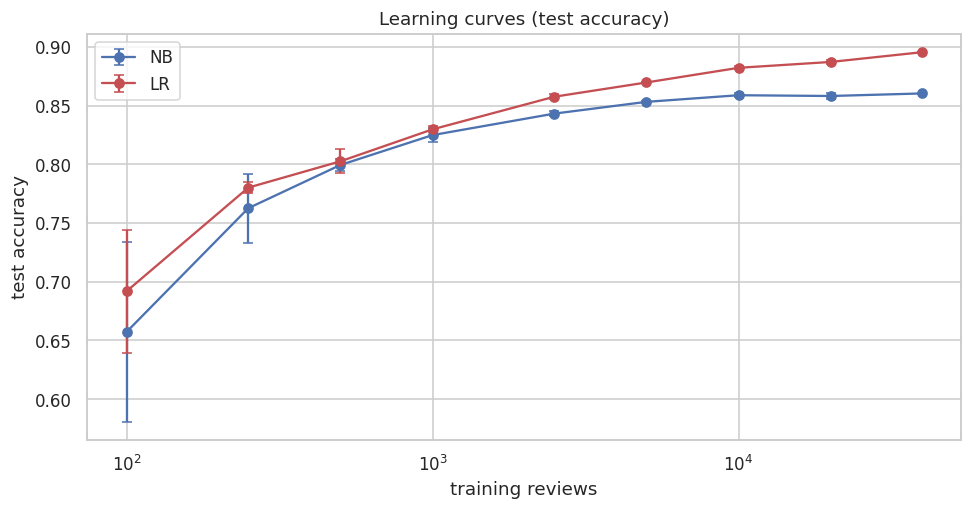

Model,LR,NB,gap_LR_minus_NB
n,,,
100,0.6918,0.6572,0.0347
250,0.7801,0.7626,0.0175
500,0.8025,0.7994,0.0031
1000,0.8298,0.8249,0.0049
2500,0.8576,0.8432,0.0144
5000,0.8697,0.8532,0.0165
10000,0.8822,0.8588,0.0233
20000,0.8872,0.8582,0.0290
39665,0.8954,0.8603,0.0351


In [19]:
sizes = [100, 250, 500, 1000, 2500, 5000, 10000, 20000, len(X_train)]
reps = {100: 8, 250: 6, 500: 5, 1000: 4, 2500: 3, 5000: 3, 10000: 2, 20000: 2, len(X_train): 1}
rng = np.random.default_rng(0)
rec = []
t0 = time.time()
for n in sizes:
    for r in range(reps[n]):
        ii = rng.choice(len(X_train), n, replace=False)
        for mname, ng, mk in [("NB", ng_nb, lambda: MultinomialNB(alpha=gs_nb.best_params_["clf__alpha"])),
                              ("LR", ng_lr, lambda: LogisticRegression(C=gs_lr.best_params_["clf__C"], max_iter=3000))]:
            v = tfidf(ng); A = v.fit_transform(X_train[ii]); 
            rec.append({"n": n, "Model": mname, "Accuracy": mk().fit(A, y_train[ii]).score(v.transform(X_test), y_test)})
print(f"learning curves took {time.time() - t0:.0f}s")
lc = pd.DataFrame(rec)
s = lc.groupby(["n", "Model"])["Accuracy"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.8))
for mname, c in [("NB", "C0"), ("LR", "C3")]:
    d = s[s.Model == mname]; ax.errorbar(d.n, d["mean"], yerr=d["std"].fillna(0), marker="o", color=c, capsize=3, label=mname)
ax.set_xscale("log"); ax.set_xlabel("training reviews"); ax.set_ylabel("test accuracy"); ax.set_title("Learning curves (test accuracy)"); ax.legend()
plt.tight_layout(); plt.show()
display(s.pivot(index="n", columns="Model", values="mean").assign(gap_LR_minus_NB=lambda d: d.LR - d.NB).style.format("{:.4f}"))

**Does Naive Bayes win with little data? Not here.**

- **LR is at least as good as NB at every training size.** With 100 reviews both are poor and very noisy (SD of several points across repeats), so the 3.5-point gap there is not meaningful; at **500–1,000 reviews they are essentially tied** (gap 0.3–0.5 points); from 2,500 reviews on, LR pulls steadily ahead.
- **NB plateaus around 86 %** after roughly 10,000 reviews, whereas LR keeps improving (88.2 % at 10k → 89.5 % at 40k) and has not clearly saturated, so more labelled data would help LR more than NB (which instead benefits more from a larger vocabulary, Section 5.3).
- Both models get to 84–86 % with only 2,500 labelled reviews, so a small labelled set is already useful.

## 9. Domain shift: do models trained on long reviews work on short phrases?

`predict_sentiment()` will mostly receive **short** inputs (a sentence or two), whereas the IMDB reviews average ~230 words. To measure the gap we use the Rotten Tomatoes snippet dataset (mean ≈ 21 words) and train three kinds of model, then evaluate each on *both* held-out test sets:

- **Long model:** trained on IMDB only (what we built above).
- **Short model:** trained on RT snippets only (hyper-parameters tuned by 5-fold CV on RT).
- **Combined model:** trained on IMDB + RT together.

In [20]:
def read_rt(name):
    url = f"https://raw.githubusercontent.com/dennybritz/cnn-text-classification-tf/master/data/rt-polaritydata/rt-polarity.{name}"
    try:
        return urllib.request.urlopen(url, timeout=30).read().decode("latin-1").splitlines()
    except Exception:
        return open(f"rt.{name}", encoding="latin-1").read().splitlines()

pos, neg = read_rt("pos"), read_rt("neg")
rt = pd.DataFrame({"review": pos + neg, "y": [1] * len(pos) + [0] * len(neg)})
rt = rt[rt["review"].str.strip() != ""].drop_duplicates("review").reset_index(drop=True)
rt["n_words"] = rt["review"].str.split().str.len()
rt["clean"] = preprocess_batch(rt["review"].to_numpy(dtype=object))
print(f"Rotten Tomatoes snippets: {len(rt):,} (after de-duplication) | positive share = {rt.y.mean():.3f} | mean words = {rt.n_words.mean():.1f} (IMDB: {df.n_words.mean():.0f})")
rt_tr, rt_te = train_test_split(np.arange(len(rt)), test_size=0.20, stratify=rt["y"], random_state=RS)
Xr_tr, Xr_te, yr_tr, yr_te = rt["clean"].to_numpy(dtype=object)[rt_tr], rt["clean"].to_numpy(dtype=object)[rt_te], rt["y"].values[rt_tr], rt["y"].values[rt_te]

# tune the short-text models on RT only (training portion)
cv5 = StratifiedKFold(5, shuffle=True, random_state=RS)
gs_nb_r = GridSearchCV(Pipeline([("tfidf", tfidf((1, 2))), ("clf", MultinomialNB())]), {"clf__alpha": [0.1, 0.3, 0.5, 1.0, 2.0]}, cv=cv5).fit(Xr_tr, yr_tr)
gs_lr_r = GridSearchCV(Pipeline([("tfidf", tfidf((1, 2))), ("clf", LogisticRegression(max_iter=3000))]), {"clf__C": [0.1, 0.3, 1, 3, 10]}, cv=cv5).fit(Xr_tr, yr_tr)
print("RT-tuned params:  NB", gs_nb_r.best_params_, "| LR", gs_lr_r.best_params_, f"| CV acc NB {gs_nb_r.best_score_:.3f}, LR {gs_lr_r.best_score_:.3f}")

Rotten Tomatoes snippets: 10,662 (after de-duplication) | positive share = 0.500 | mean words = 21.0 (IMDB: 231)


RT-tuned params:  NB {'clf__alpha': 0.3} | LR {'clf__C': 3} | CV acc NB 0.761, LR 0.757


Trained on,Model,IMDB test,RT test
Long (IMDB-trained),NB,0.8603,0.7042
Long (IMDB-trained),LR,0.8954,0.7037
Short (RT-trained),NB,0.7446,0.7684
Short (RT-trained),LR,0.7806,0.7689
Combined (IMDB + RT),NB,0.8612,0.7234
Combined (IMDB + RT),LR,0.8952,0.7436


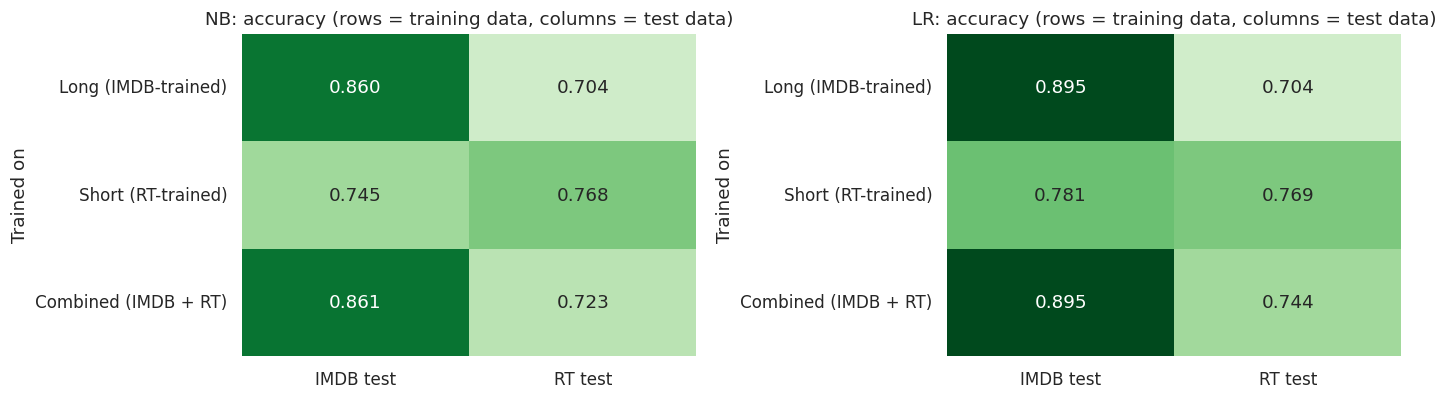

In [21]:
def fit_pair(Xtr_, ytr_, nb_est, lr_est):
    return {"NB": clone(nb_est).fit(Xtr_, ytr_), "LR": clone(lr_est).fit(Xtr_, ytr_)}

long_m  = {"NB": gs_nb.best_estimator_, "LR": gs_lr.best_estimator_}
short_m = {"NB": gs_nb_r.best_estimator_, "LR": gs_lr_r.best_estimator_}
comb_m  = fit_pair(np.r_[X_train, Xr_tr], np.r_[y_train, yr_tr], gs_nb.best_estimator_, gs_lr.best_estimator_)   # IMDB-tuned settings
sets = {"IMDB test": (X_test, y_test), "RT test": (Xr_te, yr_te)}

rows = []
for mk, mm in [("Long (IMDB-trained)", long_m), ("Short (RT-trained)", short_m), ("Combined (IMDB + RT)", comb_m)]:
    for mname in ["NB", "LR"]:
        r = {"Trained on": mk, "Model": mname}
        for sname, (Xs_, ys_) in sets.items():
            r[sname] = accuracy_score(ys_, mm[mname].predict(Xs_))
        rows.append(r)
shift = pd.DataFrame(rows)
display(shift.style.format({"IMDB test": "{:.4f}", "RT test": "{:.4f}"}).background_gradient(subset=["IMDB test", "RT test"], cmap="Greens", vmin=.65, vmax=.9).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, mname in zip(axes, ["NB", "LR"]):
    h = shift[shift.Model == mname].set_index("Trained on")[["IMDB test", "RT test"]]
    sns.heatmap(h, annot=True, fmt=".3f", cmap="Greens", vmin=.65, vmax=.9, cbar=False, ax=ax, annot_kws={"size": 12}); ax.set_title(f"{mname}: accuracy (rows = training data, columns = test data)")
plt.tight_layout(); plt.show()

**Accuracy (rows: training data; columns: test data)**

| Trained on | NB: IMDB test | NB: RT test | LR: IMDB test | LR: RT test |
|---|---|---|---|---|
| Long (IMDB only) | 0.860 | **0.704** | 0.895 | **0.704** |
| Short (RT only) | 0.745 | 0.768 | 0.781 | 0.769 |
| Combined | 0.861 | 0.723 | 0.895 | 0.744 |

- **The long-review models collapse on short text**: from 86–90 % on IMDB down to **≈ 70 %** on one-sentence snippets, a drop of 16–19 points. A bag-of-words model trained on 230-word essays has seen few of the terms, and little of the style, used in a one-line verdict.
- **A model trained on snippets does better on snippets (≈ 77 %)** but is much worse on long reviews (75–78 %), partly because it has only 8.5k short, information-poor training examples. Short snippets have far less text evidence per example, so the achievable ceiling with these features is much lower than for long reviews.
- **Mixing the data does not solve it.** The combined models match the long-only models on IMDB, but recover only part of the gap on snippets (NB 0.723, LR 0.744 vs 0.769 for the short-only model), because the 40k long reviews dominate the vocabulary and weights.
- **Takeaway:** the 89.5 % headline accuracy applies to *long movie reviews*. For short live phrases, expect ≈ 70–77 % (and no measurement at all for product text).

In [22]:
# A length-based router: use the short-text model for short inputs and the long-review model otherwise.
# The cut-off is derived from TRAINING lengths only (99th percentile of RT training snippets) -- no labels or test data involved.
THR = int(math.ceil(np.percentile(rt["n_words"].values[rt_tr], 99)))
print(f"Router threshold: inputs with <= {THR} words use the short-text model, longer inputs use the long-review model")

def route_predict(mname, raw_texts, clean_texts, n_words):
    short = n_words <= THR
    out = np.zeros(len(clean_texts), dtype=int)
    if short.any(): out[short] = short_m[mname].predict(np.asarray(clean_texts)[short])
    if (~short).any(): out[~short] = long_m[mname].predict(np.asarray(clean_texts)[~short])
    return out

nw_imdb, nw_rt = df["n_words"].values[idx_test], rt["n_words"].values[rt_te]
rows = []
for mname in ["NB", "LR"]:
    r_im = route_predict(mname, None, X_test, nw_imdb); r_rt = route_predict(mname, None, Xr_te, nw_rt)
    ally = np.r_[y_test, yr_te]
    for nm, p_im, p_rt in [("Long only", long_m[mname].predict(X_test), long_m[mname].predict(Xr_te)),
                           ("Short only", short_m[mname].predict(X_test), short_m[mname].predict(Xr_te)),
                           ("Combined", comb_m[mname].predict(X_test), comb_m[mname].predict(Xr_te)),
                           ("Router (by length)", r_im, r_rt)]:
        rows.append({"Model": mname, "Strategy": nm, "IMDB test": accuracy_score(y_test, p_im), "RT test": accuracy_score(yr_te, p_rt),
                     "Macro-average of the two domains": (accuracy_score(y_test, p_im) + accuracy_score(yr_te, p_rt)) / 2})
display(pd.DataFrame(rows).set_index(["Model", "Strategy"]).style.format("{:.4f}").background_gradient(cmap="Greens", subset=["Macro-average of the two domains"]))
print(f"Share of IMDB test reviews routed to the short model: {(nw_imdb <= THR).mean():.1%} | share of RT test snippets routed to the long model: {(nw_rt > THR).mean():.1%}")

Router threshold: inputs with <= 46 words use the short-text model, longer inputs use the long-review model


Share of IMDB test reviews routed to the short model: 1.8% | share of RT test snippets routed to the long model: 0.1%


**A simple length router gets the best of both worlds.**

| Strategy | LR: IMDB | LR: RT | LR: macro-average | NB: macro-average |
|---|---|---|---|---|
| Long only | 0.895 | 0.704 | 0.800 | 0.782 |
| Short only | 0.781 | 0.769 | 0.775 | 0.757 |
| Combined | 0.895 | 0.744 | 0.819 | 0.792 |
| **Router (by length)** | **0.894** | **0.769** | **0.831** | **0.813** |

Routing on word count keeps the long-review accuracy (−0.15 points) while matching the snippet specialist on short text, and beats the combined model by about 1.2 points (LR) and 2.1 points (NB) on the macro average.
The 46-word threshold comes from the **training** snippet lengths only (their 99th percentile), with no labels or test data involved, and in practice it separates the two sources almost perfectly (only 1.8 % of IMDB test reviews are routed short, 0.1 % of RT snippets are routed long).
Caveat: with only two data sources, inputs of intermediate length (≈ 50–100 words, typical of a real product review) go to the long-review model, and its accuracy in that range is untested. `predict_sentiment()` uses this router.

### 9.1 Can explicit negation marking fix negation in short text?

The live-phrase demo in Section 10 exposes a weakness: a bag-of-words model sees `not` and `enjoy` as independent words. In Section 4 the `not_` prefix (e.g. `not_enjoy`) gave no benefit on long reviews once bigrams were used, but short text might behave differently.
Each setting below is tuned by 5-fold CV on the RT **training** split only; the RT test split is used once per setting for the final number.

In [5]:
# Does explicit negation marking (prefix "not_" to the next words after a negator) rescue short-text negation?
# Each setting is tuned by 5-fold CV on the RT TRAINING split only; the RT test split is used once for the final number.
neg_phrases = ["I didn't enjoy this film at all", "Not bad at all, actually quite good", "This is not a good movie", "I would not recommend this to anyone"]
settings = [("keep negations (reference)", {}), ("+ not_ marking, scope 2", dict(mark_negation=True, neg_scope=2)),
            ("+ not_ marking, scope 3", dict(mark_negation=True, neg_scope=3)), ("+ not_ marking, scope 4", dict(mark_negation=True, neg_scope=4))]
y_rt = rt["y"].values
rows, phrase_rows = [], []
for name, kw in settings:
    Xk = np.array(preprocess_batch(rt["review"].to_numpy(dtype=object), **kw), dtype=object)
    for mname, grid, est in [("NB", {"clf__alpha": [0.3, 0.5, 1.0]}, MultinomialNB()), ("LR", {"clf__C": [1, 3, 10]}, LogisticRegression(max_iter=3000))]:
        g = GridSearchCV(Pipeline([("tfidf", tfidf((1, 2))), ("clf", est)]), grid, cv=cv5).fit(Xk[rt_tr], y_rt[rt_tr])
        rows.append({"Preprocessing": name, "Model": mname, "5-fold CV acc.": g.best_score_, "RT test acc.": g.score(Xk[rt_te], y_rt[rt_te])})
        if mname == "LR":
            pr = g.predict_proba(np.array(preprocess_batch(neg_phrases, **kw), dtype=object))[:, 1]
            phrase_rows.append({"Preprocessing": name, **{p: v for p, v in zip(neg_phrases, pr)}})
display(pd.DataFrame(rows).pivot(index="Preprocessing", columns="Model", values=["5-fold CV acc.", "RT test acc."]).loc[[s[0] for s in settings]].style.format("{:.4f}"))
display(pd.DataFrame(phrase_rows).set_index("Preprocessing").style.format("{:.2f}").set_caption("Short-text LR: P(positive) for negated phrases (should be low, low, low; but 'Not bad at all, actually quite good' should be high)"))

,I didn't enjoy this film at all,"Not bad at all, actually quite good",This is not a good movie,I would not recommend this to anyone
Preprocessing,,,,
keep negations (reference),0.72,0.36,0.19,0.15
"+ not_ marking, scope 2",0.47,0.77,0.13,0.17
"+ not_ marking, scope 3",0.44,0.77,0.13,0.15
"+ not_ marking, scope 4",0.45,0.78,0.13,0.16


**Result.** Averaged over the whole RT test set, negation marking makes **no measurable difference**: test accuracy moves by between −0.6 and +0.5 points (scope-4 LR even loses 0.6) and 5-fold CV accuracy by between −0.4 and +0.4 points, well inside noise.
On four hand-picked negated phrases, scope-2/3 marking changes the outputs in the right direction: *"Not bad at all, actually quite good"* goes from 0.36 to **0.77** (now correct) and *"I didn't enjoy this film at all"* from 0.72 to **0.47** (no longer confidently positive, though still not negative); the two other phrases were already right.

**Why we did not adopt it.** I chose those phrases *after* seeing the failures, so this is anecdotal evidence, and the benchmark shows no gain. The rule used throughout this notebook is to adopt a change only if it measurably improves held-out accuracy, so the deployed models keep the plain preprocessing.
Marking appears to be harmless, so for an application dominated by negated phrasing it is a reasonable switch (`preprocess(..., mark_negation=True)` and retrain). A systematic fix needs models that compose meaning (e.g. transformer encoders) or training data rich in negated constructions.

## 10. `predict_sentiment()`: live prediction

Design:

- **Input handling:** accepts any string (including HTML, empty strings, gibberish); non-strings and empty text return an explicit `"unknown"` instead of crashing or guessing.
- **Routing:** `domain="auto"` picks the short-text or long-review model by word count (Section 9); can be forced with `"short"` / `"long"`.
- **Model choice:** `model="lr"` (default; better in every test) or `"nb"`.
- **Calibrated honesty:** a binary classifier must always choose a side, even for neutral or nonsense text. If the confidence is below `min_confidence` (default 0.60) the label becomes **`uncertain`** (with the side it leans toward), and text with *no known vocabulary at all* returns `uncertain` instead of an arbitrary label.
- **Explanation:** returns the words that pushed the score most in each direction (LR: coefficient × TF-IDF value; NB: log-likelihood ratio × TF-IDF value).

The two stages are packaged as real `Pipeline`s that accept *raw text* (cleaning → TF-IDF → classifier), and we check that they reproduce the offline results exactly.

In [23]:
def _as_raw_pipeline(fitted_pipe):
    # prepend the text-cleaning step to an already fitted (tfidf -> clf) pipeline: raw text in, probabilities out
    return Pipeline([("clean", FunctionTransformer(preprocess_batch, validate=False).fit([""])),
                     ("tfidf", fitted_pipe.named_steps["tfidf"]), ("clf", fitted_pipe.named_steps["clf"])])

DEPLOY = {"long":  {m: _as_raw_pipeline(long_m[m]) for m in ["NB", "LR"]},
          "short": {m: _as_raw_pipeline(short_m[m]) for m in ["NB", "LR"]}}

# equivalence check: raw-text pipeline == offline path on real held-out reviews
chk_raw = df["review"].to_numpy(dtype=object)[idx_test][:300]; chk_clean = X_test[:300]
for m in ["NB", "LR"]:
    assert np.allclose(DEPLOY["long"][m].predict_proba(chk_raw), long_m[m].predict_proba(chk_clean)), m
print("raw-text deployment pipelines reproduce the offline predictions exactly")

def _explain(pipe, clean_text, top=3):
    tf, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
    x = tf.transform([clean_text]); idx_nz = x.indices; vals = x.data
    if len(idx_nz) == 0: return [], []
    w = clf.coef_[0] if hasattr(clf, "coef_") else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    names = tf.get_feature_names_out()[idx_nz]; contrib = w[idx_nz] * vals
    o = np.argsort(contrib)
    pos = [(names[i], float(contrib[i])) for i in o[::-1][:top] if contrib[i] > 0]
    neg = [(names[i], float(contrib[i])) for i in o[:top] if contrib[i] < 0]
    return pos, neg

def predict_sentiment(text, model="lr", domain="auto", min_confidence=0.60, explain=True):
    '''Classify the sentiment of a review or phrase.
    Returns a dict: label ('positive' | 'negative' | 'uncertain' | 'unknown'), p_positive, confidence, domain_model, and (optionally) the top words in each direction.'''
    model = model.upper()
    if model not in ("NB", "LR"):
        raise ValueError("model must be 'nb' or 'lr'")
    if domain not in ("auto", "short", "long"):
        raise ValueError("domain must be 'auto', 'short' or 'long'")
    if not isinstance(text, str) or not text.strip():
        return {"text": text, "label": "unknown", "reason": "empty or non-text input", "p_positive": None, "confidence": None}
    n_words = len(re.sub(r"<[^>]+>", " ", text).split())
    which = ("short" if n_words <= THR else "long") if domain == "auto" else domain
    pipe = DEPLOY[which][model]
    cleaned = preprocess(text)
    out = {"text": text, "domain_model": which, "n_words": n_words, "cleaned": cleaned}
    if pipe.named_steps["tfidf"].transform([cleaned]).nnz == 0:
        return {**out, "label": "uncertain", "reason": "no recognised vocabulary after cleaning", "p_positive": None, "confidence": None}
    p = float(pipe.predict_proba([text])[0, 1]); conf = max(p, 1 - p); side = "positive" if p >= 0.5 else "negative"
    out.update(p_positive=p, confidence=conf, label=side if conf >= min_confidence else "uncertain", leaning=side)
    if explain:
        out["pushes_positive"], out["pushes_negative"] = _explain(pipe, cleaned)
    return out

def show(text, **kw):
    r = predict_sentiment(text, **kw)
    if r["p_positive"] is None:
        print(f"{r['label'].upper():10s} ({r['reason']})   <- {str(text)[:70]!r}"); return r
    why = ", ".join(f"{w}" for w, _ in r.get("pushes_positive", [])[:2]) + (" | " if r.get("pushes_positive") and r.get("pushes_negative") else "") + ", ".join(f"{w}" for w, _ in r.get("pushes_negative", [])[:2])
    print(f"{r['label'].upper():10s} P(pos)={r['p_positive']:.2f}  [{kw.get('model', 'lr').upper()}, {r['domain_model']}-model]  <- {text[:70]!r}   (+/-: {why})")
    return r

# ---- unit tests for the function itself
r = predict_sentiment("An absolutely wonderful, moving film. Loved it!")
assert r["label"] == "positive" and 0.5 < r["p_positive"] <= 1 and abs(r["confidence"] - max(r["p_positive"], 1 - r["p_positive"])) < 1e-12
assert predict_sentiment("")["label"] == "unknown" and predict_sentiment(None)["label"] == "unknown" and predict_sentiment("   ")["label"] == "unknown"
assert predict_sentiment("!!! 123 ???")["label"] == "uncertain"
assert predict_sentiment("qwertyuiop asdfghjkl")["label"] == "uncertain"
assert predict_sentiment("<p>Wonderful <b>film</b></p>")["label"] in ("positive", "uncertain")
for m in ["nb", "lr"]:
    for d in ["auto", "short", "long"]:
        assert 0 <= predict_sentiment("pretty good", model=m, domain=d)["p_positive"] <= 1
try:
    predict_sentiment("x", model="svm"); raise SystemExit("should have raised")
except ValueError:
    pass
print("predict_sentiment unit tests passed")

raw-text deployment pipelines reproduce the offline predictions exactly
predict_sentiment unit tests passed


### 10.1 Trying it on custom phrases

The phrases below are hand-written (movie and product domain, plus deliberately hard cases). "Expected" is my own judgement for the clear-cut ones; mixed / neutral phrases are left unlabelled because there is no right answer.
This is a **qualitative demo on ~25 phrases, not a benchmark**; the measured accuracy numbers are those in Sections 6 and 9.

In [24]:
phrases = [
    # (text, expected)  expected: 'positive' / 'negative' / None (no clear answer)
    ("An absolute masterpiece. The acting was superb and I was moved to tears.", "positive"),
    ("A dull, predictable mess. I checked my watch every five minutes.", "negative"),
    ("I loved every minute of it", "positive"),
    ("I didn't enjoy this film at all", "negative"),
    ("This is not a good movie", "negative"),
    ("Not bad at all, actually quite good", "positive"),
    ("The plot was boring but the acting was superb", None),
    ("Oh great, another sequel nobody asked for. Just what the world needed.", "negative"),
    ("Terrible product, stopped working after two days", "negative"),
    ("Great value for the money, works perfectly", "positive"),
    ("Battery life is amazing and the screen is gorgeous", "positive"),
    ("Do not buy this. Complete waste of money.", "negative"),
    ("Absolutely love it, would buy again", "positive"),
    ("It arrived on time", None),
    ("It was fine, I guess", None),
    ("THIS IS THE WORST THING EVER", "negative"),
    ("<p>Wonderful <b>film</b>, highly recommended!</p>", "positive"),
    ("Fast shipping and the item was exactly as described", "positive"),
    ("The customer service was rude and unhelpful", "negative"),
    ("I would not recommend this to anyone", "negative"),
]
rows = []
for text, exp in phrases:
    row = {"Phrase": text if len(text) < 78 else text[:75] + "...", "Expected": exp or "-"}
    for m in ["nb", "lr"]:
        r = predict_sentiment(text, model=m, explain=False)
        row[f"{m.upper()} P(pos)"] = r["p_positive"]; row[f"{m.upper()} label"] = r["label"]
    rows.append(row)
demo = pd.DataFrame(rows)
display(demo.style.format({"NB P(pos)": "{:.2f}", "LR P(pos)": "{:.2f}"}, na_rep="-").hide(axis="index"))

clear = demo[demo["Expected"] != "-"]
summ = {}
for m in ["NB", "LR"]:
    right = (clear[f"{m} label"] == clear["Expected"]).sum(); unc = (clear[f"{m} label"] == "uncertain").sum()
    wrong = len(clear) - right - unc
    summ[m] = {"clear-cut phrases": len(clear), "correct": int(right), "abstained (uncertain)": int(unc), "wrong": int(wrong)}
display(pd.DataFrame(summ).T)

Phrase,Expected,NB P(pos),NB label,LR P(pos),LR label
An absolute masterpiece. The acting was superb and I was moved to tears.,positive,0.85,positive,0.94,positive
"A dull, predictable mess. I checked my watch every five minutes.",negative,0.06,negative,0.03,negative
I loved every minute of it,positive,0.38,negative,0.41,uncertain
I didn't enjoy this film at all,negative,0.58,uncertain,0.72,positive
This is not a good movie,negative,0.29,negative,0.19,negative
"Not bad at all, actually quite good",positive,0.23,negative,0.36,negative
The plot was boring but the acting was superb,-,0.20,negative,0.04,negative
"Oh great, another sequel nobody asked for. Just what the world needed.",negative,0.34,negative,0.51,uncertain
"Terrible product, stopped working after two days",negative,0.13,negative,0.15,negative
"Great value for the money, works perfectly",positive,0.59,uncertain,0.70,positive


,clear-cut phrases,correct,abstained (uncertain),wrong
NB,17,10,3,4
LR,17,11,3,3


In [25]:
# explanations for a few phrases: which words pushed the score up / down?
for t in ["I didn't enjoy this film at all", "The plot was boring but the acting was superb", "Great value for the money, works perfectly"]:
    r = predict_sentiment(t, model="lr")
    print(f"{t!r}\n   label = {r['label']} (P(pos) = {r['p_positive']:.2f}, {r['domain_model']}-model)  cleaned = {r['cleaned']!r}")
    print("   pushes toward positive:", [(w, round(c, 2)) for w, c in r["pushes_positive"]])
    print("   pushes toward negative:", [(w, round(c, 2)) for w, c in r["pushes_negative"]], "\n")

"I didn't enjoy this film at all"
   label = positive (P(pos) = 0.72, short-model)  cleaned = 'not enjoy film'
   pushes toward positive: [('enjoy', 1.72), ('film', 0.46)]
   pushes toward negative: [('not', -1.09)] 

'The plot was boring but the acting was superb'
   label = negative (P(pos) = 0.04, short-model)  cleaned = 'plot bore act superb'
   pushes toward positive: [('superb', 0.15), ('act', 0.12)]
   pushes toward negative: [('bore', -2.58), ('plot', -0.66)] 

'Great value for the money, works perfectly'
   label = positive (P(pos) = 0.70, short-model)  cleaned = 'great value money work perfectly'
   pushes toward positive: [('perfectly', 1.02), ('great', 0.7), ('work', 0.68)]
   pushes toward negative: [('money', -1.07), ('value', -0.37)] 



**Reading the demo (20 hand-written phrases; a qualitative check, not a benchmark)**

On the 17 phrases with a clear expected answer, **LR got 11 right, abstained on 3 ("uncertain") and got 3 wrong; NB got 10 right, abstained on 3 and got 4 wrong.** That is ≈ 79 % correct among the phrases LR committed to, which is in line with the 70–77 % short-text accuracy measured in Section 9, and far below the 89.5 % long-review headline.

*What works:* strongly worded sentiment is handled confidently by both models (*masterpiece*, *dull, predictable mess*, *amazing … gorgeous*, *waste of money*, *WORST THING EVER*), including product phrases and HTML input.

*What fails, and why:*
1. **Negation does not compose.** *"I didn't enjoy this film at all"* is called **positive** (0.72) by LR: the explanation shows `enjoy` (+1.72) outweighing the lone `not` (−1.09). *"Not bad at all, actually quite good"* is called negative by both models. Section 9.1 shows `not_` marking would improve these particular phrases but not the benchmark.
2. **Unseen vocabulary.** *"Fast shipping and the item was exactly as described"* is called negative (0.11) because shipping/item vocabulary is absent from movie and snippet training data, and NB calls *"The customer service was rude and unhelpful"* **positive** (0.67; LR is uncertain at 0.55).
3. **Corpus-specific associations.** *"I loved every minute of it"* is not recognised as positive (LR uncertain, NB negative), because "minute" occurs mostly in complaints such as "waste of minutes" in movie reviews.
4. **Sarcasm** (*"Oh great, another sequel nobody asked for"*) is only caught by NB, and LR abstains.

*Neutral text:* a binary classifier has to pick a side. NB abstains on *"It was fine, I guess"* and *"It arrived on time"*, but LR commits (positive 0.69 and negative 0.37), because its confidence is above the 0.60 cut-off. The abstention band helps but does not turn the model into a neutral-class detector; text with no known vocabulary (e.g. *"meh"*) is correctly flagged as uncertain.

The explanations (the words behind each score) make these failures easy to diagnose, which is their main practical use.

### 10.2 Interactive use

To try your own phrases, call `predict_sentiment("your text")` in any cell, or run the helper below, which loops on keyboard input (blank line to quit). It is *defined* but not *called* here, because notebook execution without a keyboard cannot read `input()`.

In [26]:
def interactive_session(model="lr"):
    print("Type a review and press Enter (blank line to quit).")
    while True:
        s = input("review> ")
        if not s.strip():
            print("bye"); break
        show(s, model=model)

# interactive_session()          # <- uncomment and run to type phrases live

# quick scripted demonstration of the same loop body:
for s in ["Best purchase I've made all year!", "Awful. Returned it immediately.", "meh"]:
    show(s)

POSITIVE   P(pos)=0.95  [LR, short-model]  <- "Best purchase I've made all year!"   (+/-: best, year)
NEGATIVE   P(pos)=0.27  [LR, short-model]  <- 'Awful. Returned it immediately.'   (+/-: return | awful)
UNCERTAIN  (no recognised vocabulary after cleaning)   <- 'meh'


## 11. Conclusions

1. **Data.** The starter link returns HTTP 404, so the work uses the IMDB 50k movie reviews (49,582 after removing 418 duplicate reviews that could have leaked between train and test) plus the Rotten Tomatoes snippets for the short-text question. No labelled product-review set was reachable.
2. **Headline results.** As specified (TF-IDF, `max_features=5000`, unigrams, default settings) NB scores **85.6 %** and LR **88.9 %** test accuracy. Tuned (unigrams + bigrams, still 5,000 features) they reach **86.0 %** (ROC-AUC 0.936) and **89.5 %** (95 % CI 88.9–90.1 %, ROC-AUC 0.962). **Logistic Regression is better by 3.5 points** (CI 2.9–4.1; McNemar p ≈ 10⁻²⁸), so it is the model to use; NB's advantages are speed and simplicity, not accuracy.
3. **Preprocessing is low-stakes; vocabulary size is not.** Stop-word, lemmatisation and negation-marking choices moved accuracy by less than about 1 point, with no variant surviving multiple-testing correction. The only consistent signal: deleting negations is slightly harmful. Raising `max_features` from 5,000 to 60,000 gains about +1.1 (LR) and +2.1 (NB) points.
4. **Data size.** NB does not beat LR even with little data (they tie at 500–1,000 reviews), and NB saturates near 86 % while LR keeps improving.
5. **The biggest practical risk is domain shift.** Models trained on long reviews fall to ≈ 70 % on one-sentence snippets; a snippet-trained model reaches ≈ 77 %. A length-based router (derived from training lengths only) gives the best macro-average (LR 83.1 %) and is what `predict_sentiment()` uses. Product-review accuracy was **not measured**.
6. **`predict_sentiment()`** validates its input, routes by length, returns probability, confidence, an `uncertain` label below 0.60 confidence (justified by the measured error-vs-confidence relationship) and the words behind the score. In a 20-phrase qualitative demo, LR was right on 11 of 17 clear-cut phrases, abstained on 3 and wrong on 3; failures came from negation, unseen product vocabulary, corpus-specific word associations and sarcasm. **Do not quote the 89.5 % figure for live short phrases.**
7. **Limitations and next steps:** (a) collect labelled short and product reviews (e.g. Amazon) and re-measure; (b) add character n-grams or sub-word features for typos and unseen product words; (c) use `not_` marking if negated phrasing is common; (d) increase `max_features` if model size is not a constraint; (e) calibrate probabilities (Platt scaling) if they will be quoted; (f) a three-class or rating-based target would handle neutral text, which a binary classifier cannot; (g) contextual models (transformers) are the real fix for compositional cases like negation and sarcasm.

**Using the notebook:** call `predict_sentiment("your text")` in any cell, or run `interactive_session()` (Section 10.2) to type phrases live.